In [4]:
import torch
import torch.nn
import copy
import pandas as pd

import matplotlib.pyplot as plt

from laya.pretrained import PretrainedDecisionModel
from laya.sft import evaluate
from laya.decision_reward import downstream_reward
from laya.grpo import grpo_step, generate_rollout
from laya.dataset import (
    raw_examples,
    LABELS,
    build_decision_examples,
    move_batch_to_device,
    encode_decision_batch,
)

from transformers import AutoTokenizer
import random


from laya.evaluation import eval_proba, decision_metrics

device = "cpu"

In [5]:
def load_model(checkpoint, device):
    model = PretrainedDecisionModel(
        model_name="bert-base-uncased",
        decision_hidden_dim=128,
    )

    model.load_state_dict(
        torch.load(
            checkpoint,
            map_location="cpu",
            weights_only=True,
        )
    )

    model = model.to(device)
    model.eval()

    return model

In [6]:
models = {
    "SFT": load_model(
        "../model/sft_model.pt",
        device,
    ),
    "RLCD": load_model(
        "../model/rlcd_model.pt",
        device,
    ),
    "GRPO": load_model(
        "../model/grpo_model.pt",
        device,
    ),
}

Loading weights: 100%|██████████| 199/199 [00:00<00:00, 22740.48it/s]
[transformers] BertModel LOAD REPORT from: bert-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
Loading weights: 100%|██████████| 199/199 [00:00<00:00, 21755.94it/s]
[transformers] BertModel LOAD REPORT from: bert-base-uncased
Key                                        | Status     |  

In [7]:
n_labels = len(LABELS)

cost_matrix = torch.ones(n_labels, n_labels, device=device)
cost_matrix.fill_diagonal_(0)

fraud_idx = LABELS.index("Fraud review")
cost_matrix[fraud_idx, :] = 10
cost_matrix[fraud_idx, fraud_idx] = 0

refund_idx = LABELS.index("Refunds")
billing_idx = LABELS.index("Billing")
cost_matrix[refund_idx, billing_idx] = 2
cost_matrix[billing_idx, refund_idx] = 2

In [8]:
model_name = "bert-base-uncased"

In [9]:
# train data
tokenizer = AutoTokenizer.from_pretrained(model_name)

examples = build_decision_examples(raw_examples, LABELS, seed=42)

# train valid split
rng = random.Random(123)

indices = list(range(len(examples)))
rng.shuffle(indices)

cut = 48
train_indices = indices[:cut]
validate_indices = indices[cut:]

train_examples = [examples[e] for e in train_indices]
validate_examples = [examples[e] for e in validate_indices]

train_batch = encode_decision_batch(train_examples, tokenizer)
validate_batch = encode_decision_batch(validate_examples, tokenizer)

train_targets = torch.tensor(
    [e["target"] for e in train_examples], dtype=torch.long
).to(device)
validate_targets = torch.tensor(
    [e["target"] for e in validate_examples], dtype=torch.long
).to(device)

train_batch = move_batch_to_device(train_batch, device)
validate_batch = move_batch_to_device(validate_batch, device)

In [10]:
test_batch = encode_decision_batch(
    validate_examples,
    tokenizer,
)

test_batch = {key: value.to(device) for key, value in test_batch.items()}

test_targets = torch.tensor(
    [example["target"] for example in validate_examples],
    device=device,
)

### model eval


In [11]:
results = {}

for name, model in models.items():
    model.eval()

    with torch.no_grad():
        _, probabilities, _ = model(**test_batch)

    results[name] = eval_proba(
        probabilities,
        test_targets,
        cost_matrix,
    )

In [12]:
comparison = pd.DataFrame(results).T

display(comparison.round(4))

,accuracy,nll,brier,ece,utility,review_rate,wrong_auto_rate,risk_cost
SFT,0.5833,1.7699,0.6585,0.3696,0.2917,0.4167,0.1667,0.1667
RLCD,0.4167,2.6802,0.8048,0.3305,-0.5417,0.4167,0.2500,1.0000
GRPO,0.5833,1.7699,0.6585,0.3696,0.2917,0.4167,0.1667,0.1667


### option permutation test


In [13]:
def permute_examples(examples, seed=42):
    rng = random.Random(seed)

    permuted_examples = []

    for example in examples:
        n_options = len(example["options"])

        permutation = list(range(n_options))
        rng.shuffle(permutation)

        new_options = [example["options"][i] for i in permutation]

        new_target = permutation.index(example["target"])

        permuted_examples.append(
            {
                **example,
                "options": new_options,
                "target": new_target,
                "permutation": permutation,
            }
        )

    return permuted_examples


def permutation_sensitivity(
    original_probabilities,
    permuted_probabilities,
    permuted_examples,
):
    differences = []

    for i, example in enumerate(permuted_examples):
        permutation = example["permutation"]
        n_options = len(permutation)

        original = original_probabilities[i, :n_options]

        permuted = permuted_probabilities[i, :n_options]

        restored = torch.empty_like(permuted)

        restored[permutation] = permuted

        differences.append((original - restored).abs().mean())

    return torch.stack(differences).mean()

In [14]:
thresholds = torch.linspace(
    0.5,
    0.95,
    10,
)

threshold_results = []

for threshold in thresholds:
    metrics = decision_metrics(
        probabilities,
        test_targets,
        cost_matrix,
        confidence_threshold=threshold.item(),
    )

    threshold_results.append(
        {
            "threshold": threshold.item(),
            **{key: value.item() for key, value in metrics.items()},
        }
    )

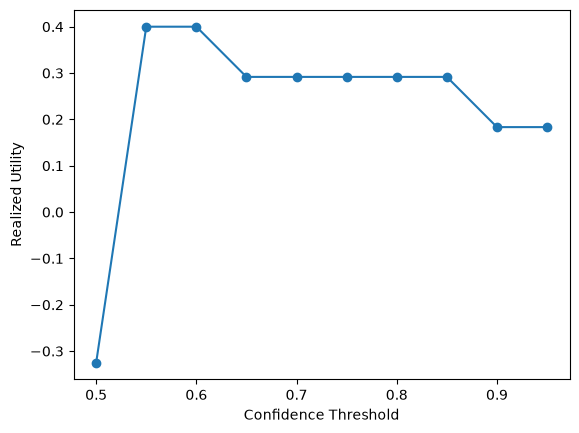

In [15]:
import matplotlib.pyplot as plt

threshold_values = [row["threshold"] for row in threshold_results]

utilities = [row["utility"] for row in threshold_results]

review_rates = [row["review_rate"] for row in threshold_results]

plt.figure()

plt.plot(
    threshold_values,
    utilities,
    marker="o",
)

plt.xlabel("Confidence Threshold")
plt.ylabel("Realized Utility")

plt.show()

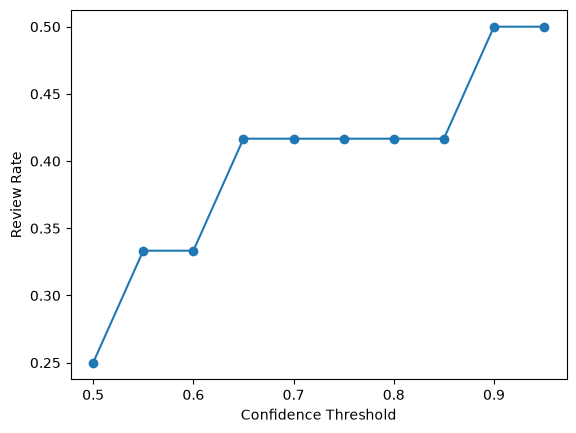

In [16]:
plt.figure()

plt.plot(
    threshold_values,
    review_rates,
    marker="o",
)

plt.xlabel("Confidence Threshold")
plt.ylabel("Review Rate")

plt.show()

In [17]:
def bootstrap_accuracy(
    probabilities,
    targets,
    n_bootstrap=1000,
    seed=42,
):
    generator = torch.Generator(device="cpu").manual_seed(seed)

    predictions = probabilities.argmax(dim=-1)

    correctness = (predictions == targets).float().cpu()

    n = len(correctness)

    estimates = []

    for _ in range(n_bootstrap):
        indices = torch.randint(
            0,
            n,
            (n,),
            generator=generator,
        )

        estimates.append(correctness[indices].mean())

    estimates = torch.stack(estimates)

    return torch.quantile(
        estimates,
        torch.tensor([0.025, 0.975]),
    )

In [18]:
lower, upper = bootstrap_accuracy(
    probabilities,
    test_targets,
)

print(f"95% CI: [{lower:.3f}, {upper:.3f}]")

95% CI: [0.333, 0.833]
